# A/B Test: Should Cookie Cats Move Its First Gate from Level 30 to Level 40?

Cookie Cats is a mobile puzzle game. At certain levels players hit a "gate" where they must wait or pay to continue. The team tested moving the first gate from level 30 to level 40 on 90,189 new players, assigned at random at install.

**Decision to make:** keep the gate at level 30, or move it to level 40?

**Primary metric:** 7-day retention (did the player come back 7 days after install).
**Secondary metrics:** 1-day retention and game rounds played in the first 14 days.

Steps:
1. Check that randomization worked (sample ratio mismatch, data quality)
2. Test retention differences with a two-proportion z-test, a bootstrap and a Bayesian model
3. Compare engagement with a test that suits heavily skewed data
4. Work out how small an effect this test could have detected
5. Make a recommendation

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.multitest import multipletests

RNG = np.random.default_rng(42)
sns.set_theme(style="whitegrid")

In [2]:
URL = "https://raw.githubusercontent.com/ryanschaub/Mobile-Games-A-B-Testing-with-Cookie-Cats/master/cookie_cats.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Sanity checks

In [3]:
print("duplicate user ids:", df["userid"].duplicated().sum())
print("missing values:", df.isna().sum().sum())
counts = df["version"].value_counts()
counts.to_frame("players")

duplicate user ids: 0
missing values: 0


,players
version,
gate_40,45489
gate_30,44700


**Sample ratio mismatch (SRM).** With a 50/50 split, group sizes this far apart could mean the assignment was broken. A chi-square goodness-of-fit test checks it.

In [4]:
chi2, p_srm = stats.chisquare(counts.values)
print(f"chi-square = {chi2:.2f}, p = {p_srm:.4f}")

chi-square = 6.90, p = 0.0086


The split is 44,700 vs 45,489. The p-value is about 0.009, so the gap is larger than chance alone usually gives. That is worth raising with the engineering team (for example, did one version crash more often at install?). The difference is under 1% of each group, and the retention results below are stated as rates, so I continue but note the issue in the recommendation.

In [5]:
df["sum_gamerounds"].describe(percentiles=[.5, .9, .99, .999]).round(1)

count    90189.0
mean        51.9
std        195.1
min          0.0
50%         16.0
90%        134.0
99%        493.0
99.9%     1073.6
max      49854.0
Name: sum_gamerounds, dtype: float64

In [6]:
top = df.nlargest(3, "sum_gamerounds")
top

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False


One player logged 49,854 rounds in 14 days, about 2.5 rounds per minute without sleep. That is almost certainly a bot or a logging error, so I drop that user.

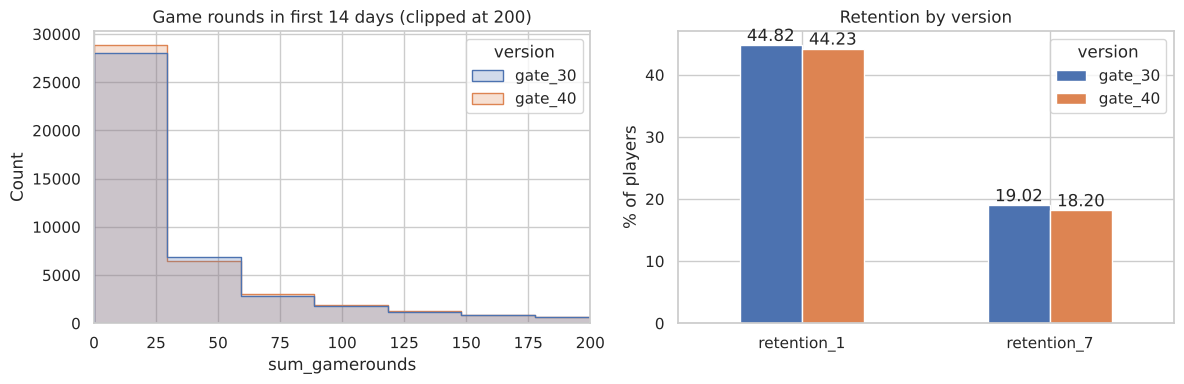

,retention_1,retention_7
version,,
gate_30,44.82,19.02
gate_40,44.23,18.20


In [7]:
df = df[df["sum_gamerounds"] < 40000].copy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="sum_gamerounds", hue="version", bins=100, element="step", ax=ax[0])
ax[0].set_xlim(0, 200); ax[0].set_title("Game rounds in first 14 days (clipped at 200)")
r = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
r.T.plot.bar(ax=ax[1], rot=0); ax[1].set_ylabel("% of players"); ax[1].set_title("Retention by version")
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.2f")
plt.tight_layout(); plt.savefig("images/overview.png", dpi=120); plt.show()
r.round(2)

## 2. Retention: frequentist test

Two-proportion z-test, two-sided, α = 0.05. The confidence interval is for the difference gate_30 − gate_40 in percentage points.

In [8]:
def compare(metric):
    g = df.groupby("version")[metric].agg(["sum", "count"])
    x30, n30 = g.loc["gate_30"]; x40, n40 = g.loc["gate_40"]
    z, p = proportions_ztest([x30, x40], [n30, n40])
    lo, hi = confint_proportions_2indep(x30, n30, x40, n40, method="wald")
    return {"metric": metric, "gate_30 %": 100 * x30 / n30, "gate_40 %": 100 * x40 / n40,
            "diff (pp)": 100 * (x30 / n30 - x40 / n40), "95% CI low": 100 * lo, "95% CI high": 100 * hi,
            "z": z, "p-value": p}

res = pd.DataFrame([compare("retention_1"), compare("retention_7")]).set_index("metric")
res["p (Holm)"] = multipletests(res["p-value"], method="holm")[1]
res.round(4)

,gate_30 %,gate_40 %,diff (pp),95% CI low,95% CI high,z,p-value,p (Holm)
metric,,,,,,,,
retention_1,44.8198,44.2283,0.5915,-0.0572,1.2403,1.7871,0.0739,0.0739
retention_7,19.0183,18.2000,0.8183,0.3103,1.3263,3.1574,0.0016,0.0032


- **7-day retention** is 0.82 points higher with the gate at 30 (19.02% vs 18.20%). The 95% interval excludes zero, and the result holds after a Holm correction for testing two metrics.
- **1-day retention** is 0.59 points higher at gate 30, but this is not significant (p ≈ 0.07).

## 3. Retention: bootstrap and Bayesian checks

The z-test relies on a normal approximation. A bootstrap makes no such assumption, and a Bayesian model answers the question the business actually asks: how likely is it that gate 30 is better?

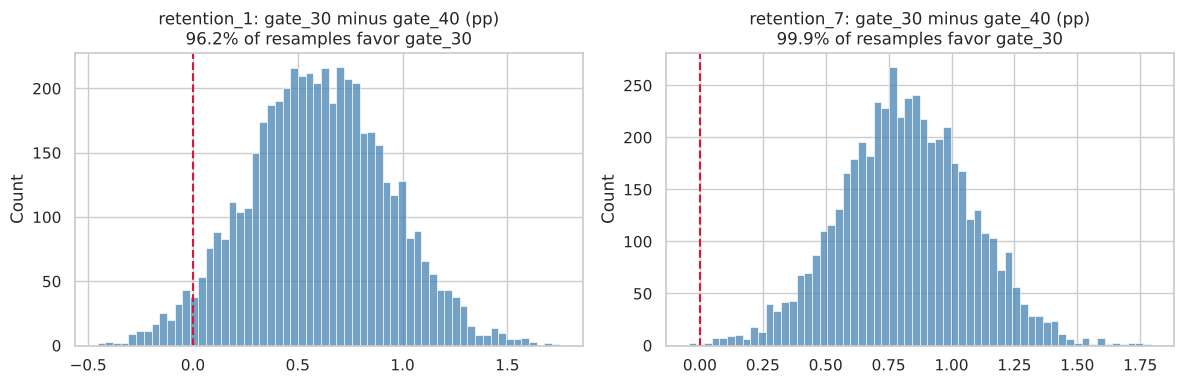

In [9]:
def boot_diff(metric, n_boot=5000):
    a = df.loc[df.version == "gate_30", metric].values.astype(float)
    b = df.loc[df.version == "gate_40", metric].values.astype(float)
    ma = RNG.binomial(len(a), a.mean(), n_boot) / len(a)
    mb = RNG.binomial(len(b), b.mean(), n_boot) / len(b)
    return 100 * (ma - mb)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, m in zip(ax, ["retention_1", "retention_7"]):
    d = boot_diff(m)
    sns.histplot(d, bins=60, ax=a_, color="steelblue")
    a_.axvline(0, c="crimson", ls="--")
    a_.set_title(f"{m}: gate_30 minus gate_40 (pp)\n{(d > 0).mean():.1%} of resamples favor gate_30")
plt.tight_layout(); plt.savefig("images/bootstrap.png", dpi=120); plt.show()

In [10]:
# Beta-binomial with a flat Beta(1, 1) prior
def prob_30_better(metric, draws=200_000):
    g = df.groupby("version")[metric].agg(["sum", "count"])
    s30 = RNG.beta(1 + g.loc["gate_30", "sum"], 1 + g.loc["gate_30", "count"] - g.loc["gate_30", "sum"], draws)
    s40 = RNG.beta(1 + g.loc["gate_40", "sum"], 1 + g.loc["gate_40", "count"] - g.loc["gate_40", "sum"], draws)
    lift = (s30 - s40) / s40
    return {"P(gate_30 better)": (s30 > s40).mean(), "expected relative lift": lift.mean(),
            "95% credible interval": np.percentile(lift, [2.5, 97.5]).round(4).tolist()}

pd.DataFrame({m: prob_30_better(m) for m in ["retention_1", "retention_7"]}).T

,P(gate_30 better),expected relative lift,95% credible interval
retention_1,0.962945,0.013387,"[-0.0013, 0.0282]"
retention_7,0.999155,0.045015,"[0.0167, 0.074]"


All three methods agree: there is about a 99.9% probability that gate 30 gives better 7-day retention, with a relative lift of roughly 4.5%.

## 4. Engagement: game rounds

Game rounds are extremely skewed (median 16, a long tail into the thousands), so a t-test on the mean would be driven by a few heavy players. The Mann-Whitney U test compares the distributions instead.

In [11]:
a = df.loc[df.version == "gate_30", "sum_gamerounds"]
b = df.loc[df.version == "gate_40", "sum_gamerounds"]
u, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"median rounds: gate_30 {a.median():.0f}, gate_40 {b.median():.0f}")
print(f"mean rounds:   gate_30 {a.mean():.1f}, gate_40 {b.mean():.1f}")
print(f"Mann-Whitney p = {p_mw:.3f}")

median rounds: gate_30 17, gate_40 16
mean rounds:   gate_30 51.3, gate_40 51.3
Mann-Whitney p = 0.051


Rounds played are almost identical (median 17 vs 16, same mean), and the difference is not significant at α = 0.05 (p = 0.051). The gate position mainly changes whether players come back, not how much they play.

## 5. How sensitive was this test?

The minimum detectable effect (MDE) is the smallest true difference the test had an 80% chance of finding at α = 0.05. If it is larger than the effect we care about, a "no difference" result would not mean much.

In [12]:
power = NormalIndPower()
n = len(df) / 2
rows = []
for m in ["retention_1", "retention_7"]:
    base = df.loc[df.version == "gate_40", m].mean()
    for d in np.arange(0.001, 0.03, 0.0001):
        es = proportion_effectsize(base + d, base)
        if power.solve_power(effect_size=es, nobs1=n, alpha=0.05, ratio=1) >= 0.8:
            rows.append({"metric": m, "baseline %": 100 * base, "MDE (pp)": 100 * d}); break
mde = pd.DataFrame(rows).set_index("metric").round(2)
mde

,baseline %,MDE (pp)
metric,,
retention_1,44.23,0.93
retention_7,18.20,0.73


In [13]:
# Players needed per group to detect the observed 7-day effect with 80% power
base7 = df.loc[df.version == "gate_40", "retention_7"].mean()
obs7 = df.loc[df.version == "gate_30", "retention_7"].mean()
need = power.solve_power(effect_size=proportion_effectsize(obs7, base7), alpha=0.05, power=0.8, ratio=1)
print(f"needed per group: {need:,.0f} | had per group: {n:,.0f}")

needed per group: 35,502 | had per group: 45,094


The test could detect a 0.73-point change in 7-day retention. The observed effect (0.82 points) is just above that, so the test had enough players for the primary metric. For 1-day retention it could only detect about 0.93 points, so the 0.59-point difference there is inconclusive rather than absent.

## Recommendation

**Keep the first gate at level 30.**

- Moving it to level 40 lowers 7-day retention by about 0.8 points (4.3% relative). The result is significant, survives correction for two metrics and agrees across frequentist, bootstrap and Bayesian methods.
- 1-day retention and rounds played show no clear difference, which fits the idea that an earlier break makes players want to come back.
- Before the next experiment, check why group sizes differ more than expected (sample ratio mismatch, p ≈ 0.009) to rule out an assignment or logging bug.
- A useful follow-up is testing gate 20, since an earlier gate may raise long-term retention further.